# Clustering di volti/dipinti con ArcFace (InsightFace) + UMAP + HDBSCAN/DBSCAN
Versione corretta. Modifica solo la cella di configurazione.

## 1. Installazione dipendenze

In [13]:
# Esegui UNA volta (togli il "#"). Se non hai GPU NVIDIA sostituisci onnxruntime-gpu con onnxruntime.
# %pip install -q insightface onnxruntime-gpu opencv-python umap-learn hdbscan scikit-learn pandas matplotlib tqdm pillow

## 2. Configurazione e import

In [ ]:
import os
import math
import numpy as np
import pandas as pd
import cv2
import umap
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from insightface.app import FaceAnalysis
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

# hdbscan: pacchetto esterno, se manca uso quello di scikit-learn (>=1.3)
try:
    from hdbscan import HDBSCAN
except ImportError:
    from sklearn.cluster import HDBSCAN

# ── CONFIGURAZIONE ────────────────────────────────────────────
dataset_bn = r'C:\Users\Asus\Desktop\progetto_caravaggio\dataset\genere\bianco_e_nero\Female'
nome_test = "Unknown.jpg0"      # immagine da cercare nei cluster (deve stare nella cartella)
valid_extensions = ('.jpg', '.jpeg', '.png', '.webp', '.tif', '.tiff')

if not os.path.isdir(dataset_bn):
    raise FileNotFoundError(f"Cartella non trovata: {dataset_bn}")

In [15]:
def assegna_periodo(filename):
    f = filename.lower()
    if any(x in f for x in ['i_musici', 'buona_ventura', 'maddalena-pentinente', 'ramarro', 'riposo-fuga']):
        return '1. Primo Periodo Romano'
    if any(x in f for x in ['giuditta', 'marta_e_maria', 'caterina_d_alessandria', 'fillide']):
        return '2. Periodo Grandi Patroni'
    if any(x in f for x in ['deposizione', 'morte_della_vergine', 'palafrenieri', 'loreto',
                            'san_matteo_e_angelo', 'cena_in_emmaus', 'incoronazione_di_spine']):
        return '3. Maturità Romana'
    if any(x in f for x in ['golia', 'flagellazione', 'negazione', 'misericordia', 'rosario',
                            'nativita', 'salome', 'solome']):
        return '4. Periodo Esilio Tardo'
    return '5. Sconosciuto / Altro'

def read_bgr(path):
    """Legge un'immagine anche con percorsi Windows con caratteri speciali (cv2.imread in quel caso restituisce None)."""
    data = np.fromfile(path, dtype=np.uint8)
    return cv2.imdecode(data, cv2.IMREAD_COLOR)

## 3. Caricamento modello ArcFace (InsightFace)
- **Detector**: SCRFD (rilevamento del volto)
- **Recognition**: ArcFace ResNet50 (embedding a 512 dimensioni)

Uso la GPU se onnxruntime la vede, altrimenti la CPU.

In [16]:
import onnxruntime as ort

use_gpu = 'CUDAExecutionProvider' in ort.get_available_providers()
providers = ['CUDAExecutionProvider', 'CPUExecutionProvider'] if use_gpu else ['CPUExecutionProvider']
print("GPU disponibile:", use_gpu)

app = FaceAnalysis(name='buffalo_l', allowed_modules=['detection', 'recognition'], providers=providers)
app.prepare(ctx_id=0 if use_gpu else -1, det_size=(640, 640))

GPU disponibile: True
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Asus/.insightface\models\buffalo_l\1k3d68.onnx landmark_3d_68
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Asus/.insightface\models\buffalo_l\2d106det.onnx landmark_2d_106
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Asus/.insightface\models\buffalo_l\det_10g.onnx detection [1, 3, '?', '?'] 127.5 128.0
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
model ignore: C:\Users\Asus/.insightface\models\buffalo_l\genderage.onnx genderage
Applied providers: ['CPUExecutionProvider'], with options: {'CPUExecutionProvider': {}}
find model: C:\Users\Asus/.insightface\models\buffalo_l\w600k_r50.onnx recognition ['None', 3, 112, 112] 127.5 127.5
set det-size: (640, 640)


## 4. Estrazione embedding da tutte le immagini

In [17]:
all_embeddings, file_names, file_paths, skipped = [], [], [], []
n_fallback = 0

files = sorted(f for f in os.listdir(dataset_bn) if f.lower().endswith(valid_extensions))
print(f"Inizio lavoro su {len(files)} immagini...")

rec_model = app.models.get('recognition', None)

for filename in tqdm(files):
    try:
        full_path = os.path.join(dataset_bn, filename)
        img_bgr = read_bgr(full_path)
        if img_bgr is None:
            raise ValueError("Immagine non leggibile")

        faces = app.get(img_bgr)

        if len(faces) == 0:
            # Fallback: il detector non trova il volto -> embedding sull'intera immagine.
            # get_feat vuole un'immagine BGR 112x112 (fa lui stesso normalizzazione e conversione RGB).
            if rec_model is None:
                raise ValueError("Nessun volto rilevato e modello di recognition non disponibile")
            feat = rec_model.get_feat(cv2.resize(img_bgr, (112, 112))).flatten()
            norm = np.linalg.norm(feat)
            embedding = feat / norm if norm > 0 else feat
            n_fallback += 1
        else:
            # Volto principale = bounding box più grande
            face = max(faces, key=lambda f: (f.bbox[2] - f.bbox[0]) * (f.bbox[3] - f.bbox[1]))
            embedding = face.normed_embedding

        all_embeddings.append(np.asarray(embedding).flatten())
        file_names.append(filename)
        file_paths.append(full_path)

    except Exception as e:
        print(f"Errore su {filename}: {e}")
        skipped.append((filename, str(e)))

if not all_embeddings:
    raise RuntimeError("Nessun embedding estratto. Verifica il percorso delle immagini.")

X = np.vstack(all_embeddings)
print(f"\nMatrice embedding: {X.shape[0]} immagini x {X.shape[1]} features "
      f"({n_fallback} con fallback senza volto rilevato)")

df_style = pd.DataFrame({'file': file_names, 'full_path': file_paths})
df_style['periodo'] = df_style['file'].apply(assegna_periodo)

if skipped:
    print(f"\nImmagini saltate ({len(skipped)}):")
    for s_file, s_err in skipped:
        print(f" - {s_file}: {s_err}")

colori_periodi = {
    '1. Primo Periodo Romano':   '#1f77b4',
    '2. Periodo Grandi Patroni': '#ff7f0e',
    '3. Maturità Romana':        '#2ca02c',
    '4. Periodo Esilio Tardo':   '#d62728',
    '5. Sconosciuto / Altro':    '#7f7f7f',
}
path_lookup = dict(zip(file_names, file_paths))

if nome_test not in file_names:
    print(f"\n⚠️ '{nome_test}' non è tra i file analizzati: i grafici funzionano, ma senza immagine di test.")

Inizio lavoro su 44 immagini...


  0%|          | 0/44 [00:00<?, ?it/s]


Matrice embedding: 44 immagini x 512 features (44 con fallback senza volto rilevato)


In [18]:
# ── Funzioni di utilità ───────────────────────────────────────
def test_index():
    return file_names.index(nome_test) if nome_test in file_names else None

def plot_umap(labels, title):
    """Due pannelli: a sinistra colori per periodo stilistico, a destra colori per cluster."""
    idx = test_index()
    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    ax = axes[0]
    periodi = df_style['periodo'].values
    for periodo, colore in colori_periodi.items():
        m = periodi == periodo
        if m.any():
            ax.scatter(X_embedded[m, 0], X_embedded[m, 1], c=colore, label=periodo,
                       s=40, alpha=0.8, edgecolors='k', linewidths=0.5)
    ax.set_title('Per periodo stilistico')
    ax.legend(loc='best', title='Periodi')

    ax = axes[1]
    sc = ax.scatter(X_embedded[:, 0], X_embedded[:, 1], c=labels, cmap='tab20',
                    s=40, alpha=0.8, edgecolors='k', linewidths=0.5)
    fig.colorbar(sc, ax=ax, label='Cluster (-1 = rumore)')
    ax.set_title(title)

    for a in axes:
        a.grid(True, linestyle='--', alpha=0.5)
        if idx is not None:
            a.scatter(X_embedded[idx, 0], X_embedded[idx, 1], c='yellow', edgecolors='red',
                      s=250, marker='*', zorder=5, label=f"Test: {nome_test}")
    if idx is not None:
        axes[0].legend(loc='best', title='Periodi')
    plt.show()

def show_cluster(res, title):
    """Mostra le immagini del cluster che contiene nome_test. Restituisce la lista dei membri (o None)."""
    if nome_test not in res['file'].values:
        print(f"'{nome_test}' non è nel dataset.")
        return None
    cid = res.loc[res['file'] == nome_test, 'cluster'].values[0]
    print(f"'{nome_test}' -> cluster {cid}")
    if cid == -1:
        print("Classificata come RUMORE. Prova a cambiare i parametri.")
        return None
    members = res.loc[res['cluster'] == cid, 'file'].tolist()
    print(f"Cluster {cid}: {len(members)} immagini.")

    cols = 5
    rows = math.ceil(len(members) / cols)
    fig, axes = plt.subplots(rows, cols, figsize=(20, 4 * rows), squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, fn in zip(axes.ravel(), members):
        img = read_bgr(path_lookup[fn])
        if img is None:
            ax.set_title(f"Errore: {fn}", fontsize=8)
            continue
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(fn, fontsize=9, color='red' if fn == nome_test else 'black')
    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()
    return members

def similarity_report(members, label):
    """Similarità coseno (gli embedding sono normalizzati, quindi basta il prodotto scalare)."""
    idx = test_index()
    if idx is None or not members:
        return
    v = X[idx] / np.linalg.norm(X[idx])
    rows = []
    for fn in members:
        if fn == nome_test:
            continue
        w = X[file_names.index(fn)]
        rows.append({'Immagine': fn, 'Similarità Coseno': round(float(v @ (w / np.linalg.norm(w))), 4)})
    print(f"\n--- Similarità coseno {label} ({nome_test}) ---")
    if not rows:
        print("Il cluster contiene solo l'immagine di test.")
        return
    df = pd.DataFrame(rows).sort_values('Similarità Coseno', ascending=False)
    print(df.to_string(index=False))
    print(f"Similarità media: {df['Similarità Coseno'].mean():.4f}")

## 5. Riduzione dimensionale con UMAP

In [19]:
print("Avvio UMAP...")
reducer = umap.UMAP(n_neighbors=min(15, len(X) - 1), min_dist=0.1, n_components=2, random_state=42)
X_embedded = reducer.fit_transform(X)
print("Riduzione UMAP completata.")

Avvio UMAP...
Riduzione UMAP completata.


c:\Users\Asus\miniconda3\envs\caravaggio\lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


---
# BLOCCO A — HDBSCAN

Risultati HDBSCAN:
                                                                           file  cluster
36  normali_bw_Salome_con_la_cabeza_del_Bautista_(Caravaggio)_aligned_face1.jpg       -1
19                                  normali_bw_Cena_in_Emmaus_aligned_face1.jpg       -1
18                         generative_ia_bw_160054_caravaggio_aligned_face0.jpg       -1
26                      normali_bw_La_negazione_di_San_Pietro_aligned_face1.jpg       -1
24                             normali_bw_Giuditta_e_Olomerfe_aligned_face0.jpg       -1
17                         generative_ia_bw_160053_caravaggio_aligned_face0.jpg        0
16                         generative_ia_bw_160052_caravaggio_aligned_face0.jpg        0
15                         generative_ia_bw_160051_caravaggio_aligned_face0.jpg        0
13                         generative_ia_bw_160049_caravaggio_aligned_face0.jpg        0
12                         generative_ia_bw_160048_caravaggio_aligned_face0.jpg        0
11

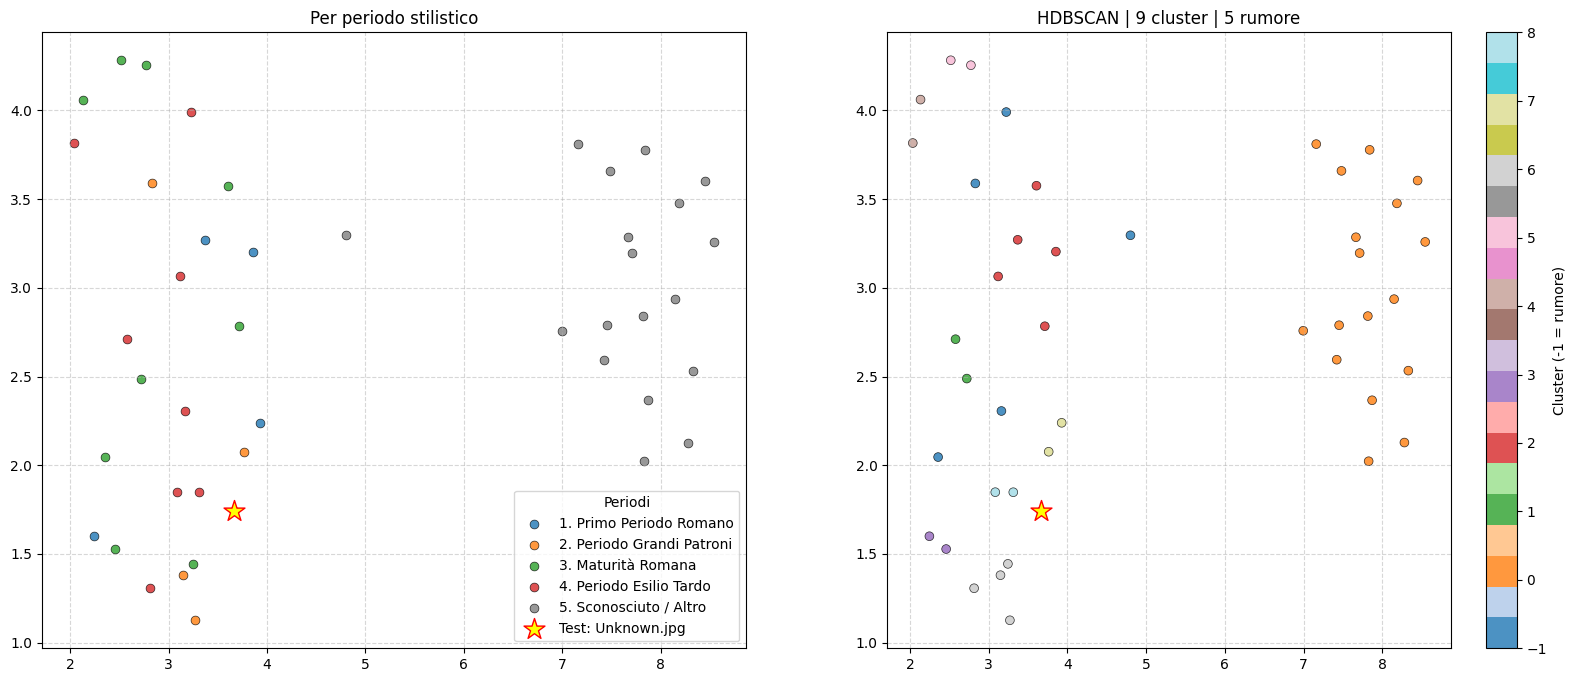

In [20]:
clusterer = HDBSCAN(min_cluster_size=2, min_samples=1, metric='euclidean')
labels = clusterer.fit_predict(X_embedded)

results = pd.DataFrame({'file': file_names, 'cluster': labels})
print("Risultati HDBSCAN:")
print(results.sort_values(by='cluster').to_string())

n_cl = len(set(labels)) - (1 if -1 in labels else 0)
plot_umap(labels, f'HDBSCAN | {n_cl} cluster | {int((labels == -1).sum())} rumore')

'Unknown.jpg' -> cluster 7
Cluster 7: 3 immagini.


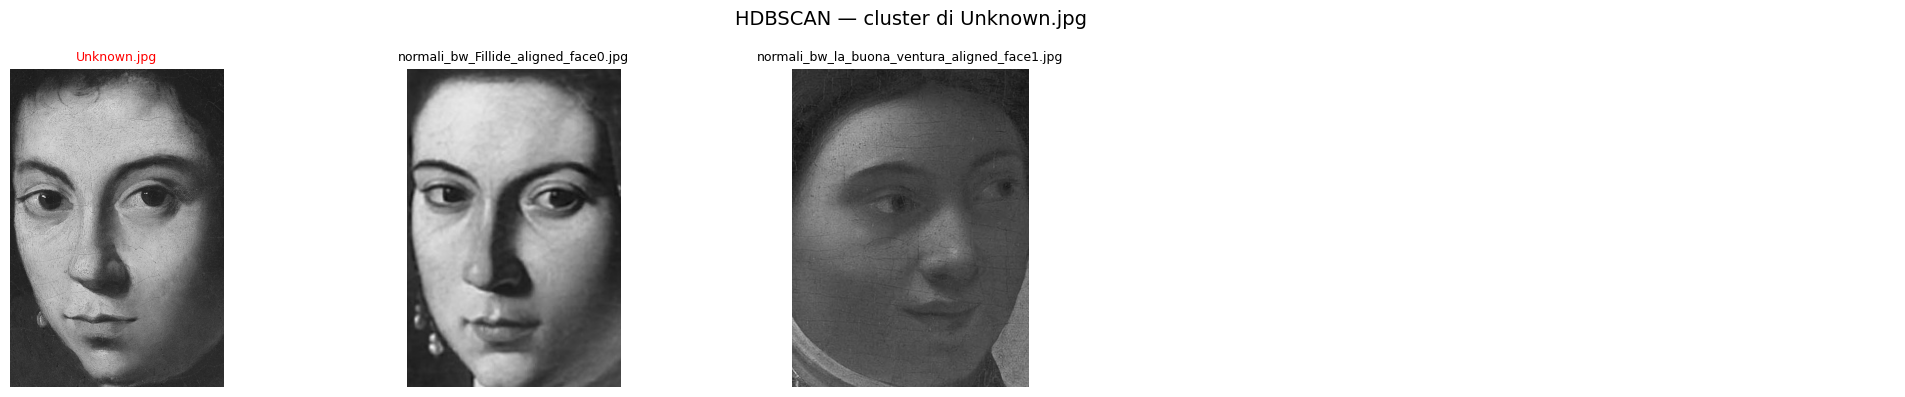


--- Similarità coseno HDBSCAN (Unknown.jpg) ---
                                     Immagine  Similarità Coseno
         normali_bw_Fillide_aligned_face0.jpg             0.4744
normali_bw_la_buona_ventura_aligned_face1.jpg             0.2611
Similarità media: 0.3678


In [21]:
members_hdb = show_cluster(results, 'HDBSCAN — cluster di ' + nome_test)
similarity_report(members_hdb, 'HDBSCAN')

---
# BLOCCO B — DBSCAN

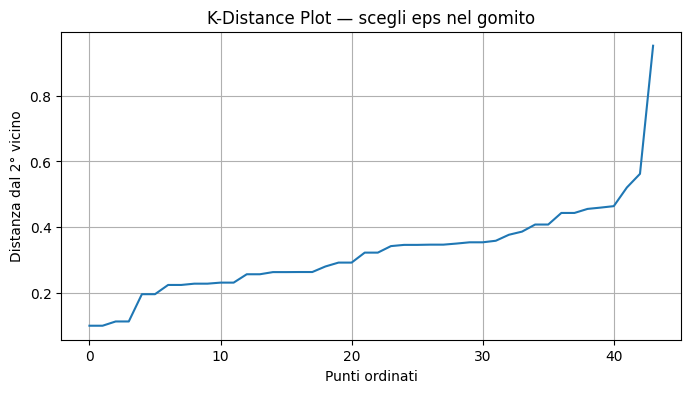

In [22]:
# K-Distance plot per scegliere eps
min_samples = 2
nn = NearestNeighbors(n_neighbors=min(min_samples, len(X_embedded))).fit(X_embedded)
distances, _ = nn.kneighbors(X_embedded)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel('Punti ordinati')
plt.ylabel(f'Distanza dal {min_samples}° vicino')
plt.title('K-Distance Plot — scegli eps nel gomito')
plt.grid(True)
plt.show()

DBSCAN — Cluster trovati: 4 | Punti rumore: 2
                                                                           file  cluster
24                             normali_bw_Giuditta_e_Olomerfe_aligned_face0.jpg       -1
18                         generative_ia_bw_160054_caravaggio_aligned_face0.jpg       -1
0                                                                   Unknown.jpg        0
41                                        normali_bw_nativita_aligned_face0.jpg        0
39                                normali_bw_la_buona_ventura_aligned_face1.jpg        0
38    normali_bw_Solome_con_la_testa_di_San_Giovanni_Battista_aligned_face1.jpg        0
37                    normali_bw_Santa_caterina_d_alessandria_aligned_face0.jpg        0
36  normali_bw_Salome_con_la_cabeza_del_Bautista_(Caravaggio)_aligned_face1.jpg        0
35                                   normali_bw_Marta_e_Maria_aligned_face0.jpg        0
31                             normali_bw_Madonna_del_rosario_al

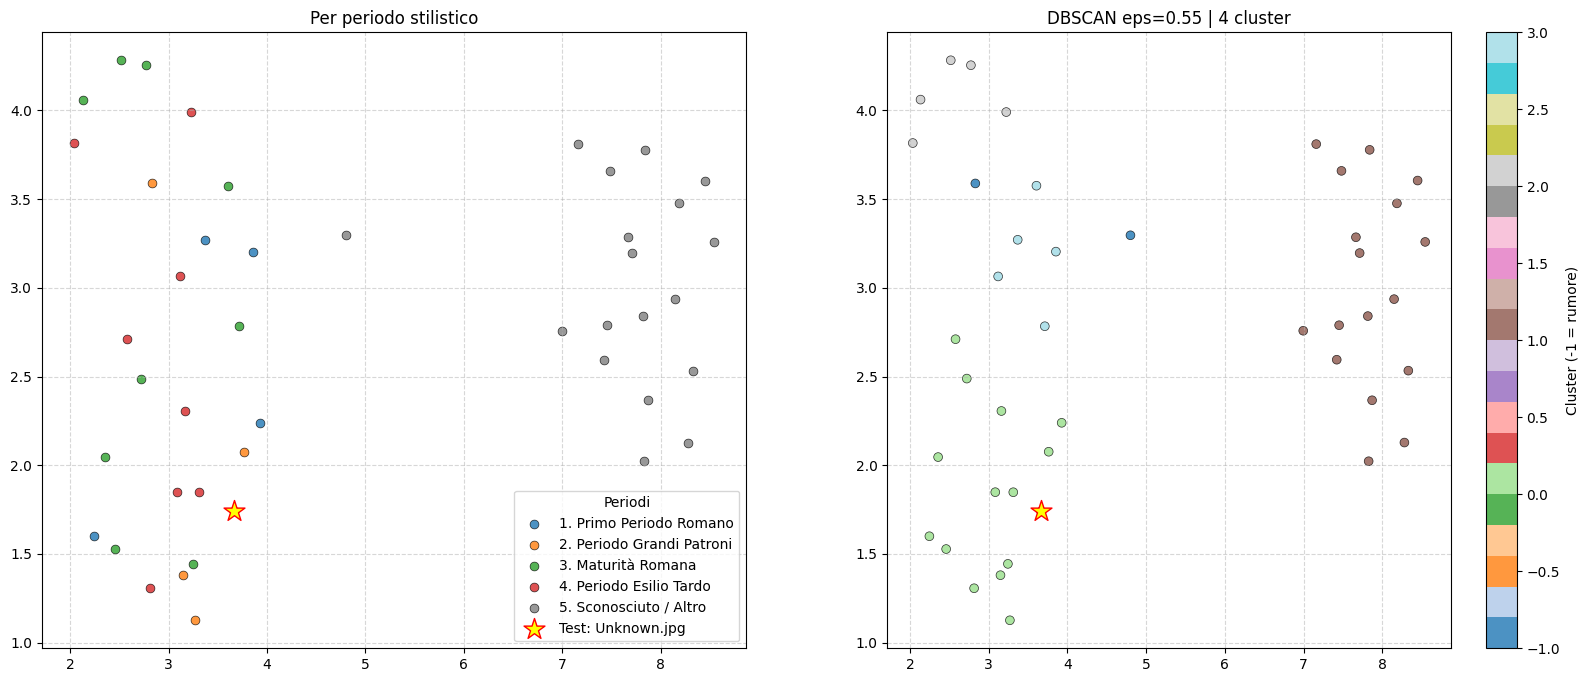

In [23]:
eps = 0.55   # <-- modificalo guardando il gomito del grafico sopra

labels_db = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_embedded)
n_cl_db = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print(f"DBSCAN — Cluster trovati: {n_cl_db} | Punti rumore: {int((labels_db == -1).sum())}")

results_db = pd.DataFrame({'file': file_names, 'cluster': labels_db})
print(results_db.sort_values(by='cluster').to_string())

plot_umap(labels_db, f'DBSCAN eps={eps} | {n_cl_db} cluster')

'Unknown.jpg' -> cluster 0
Cluster 0: 15 immagini.


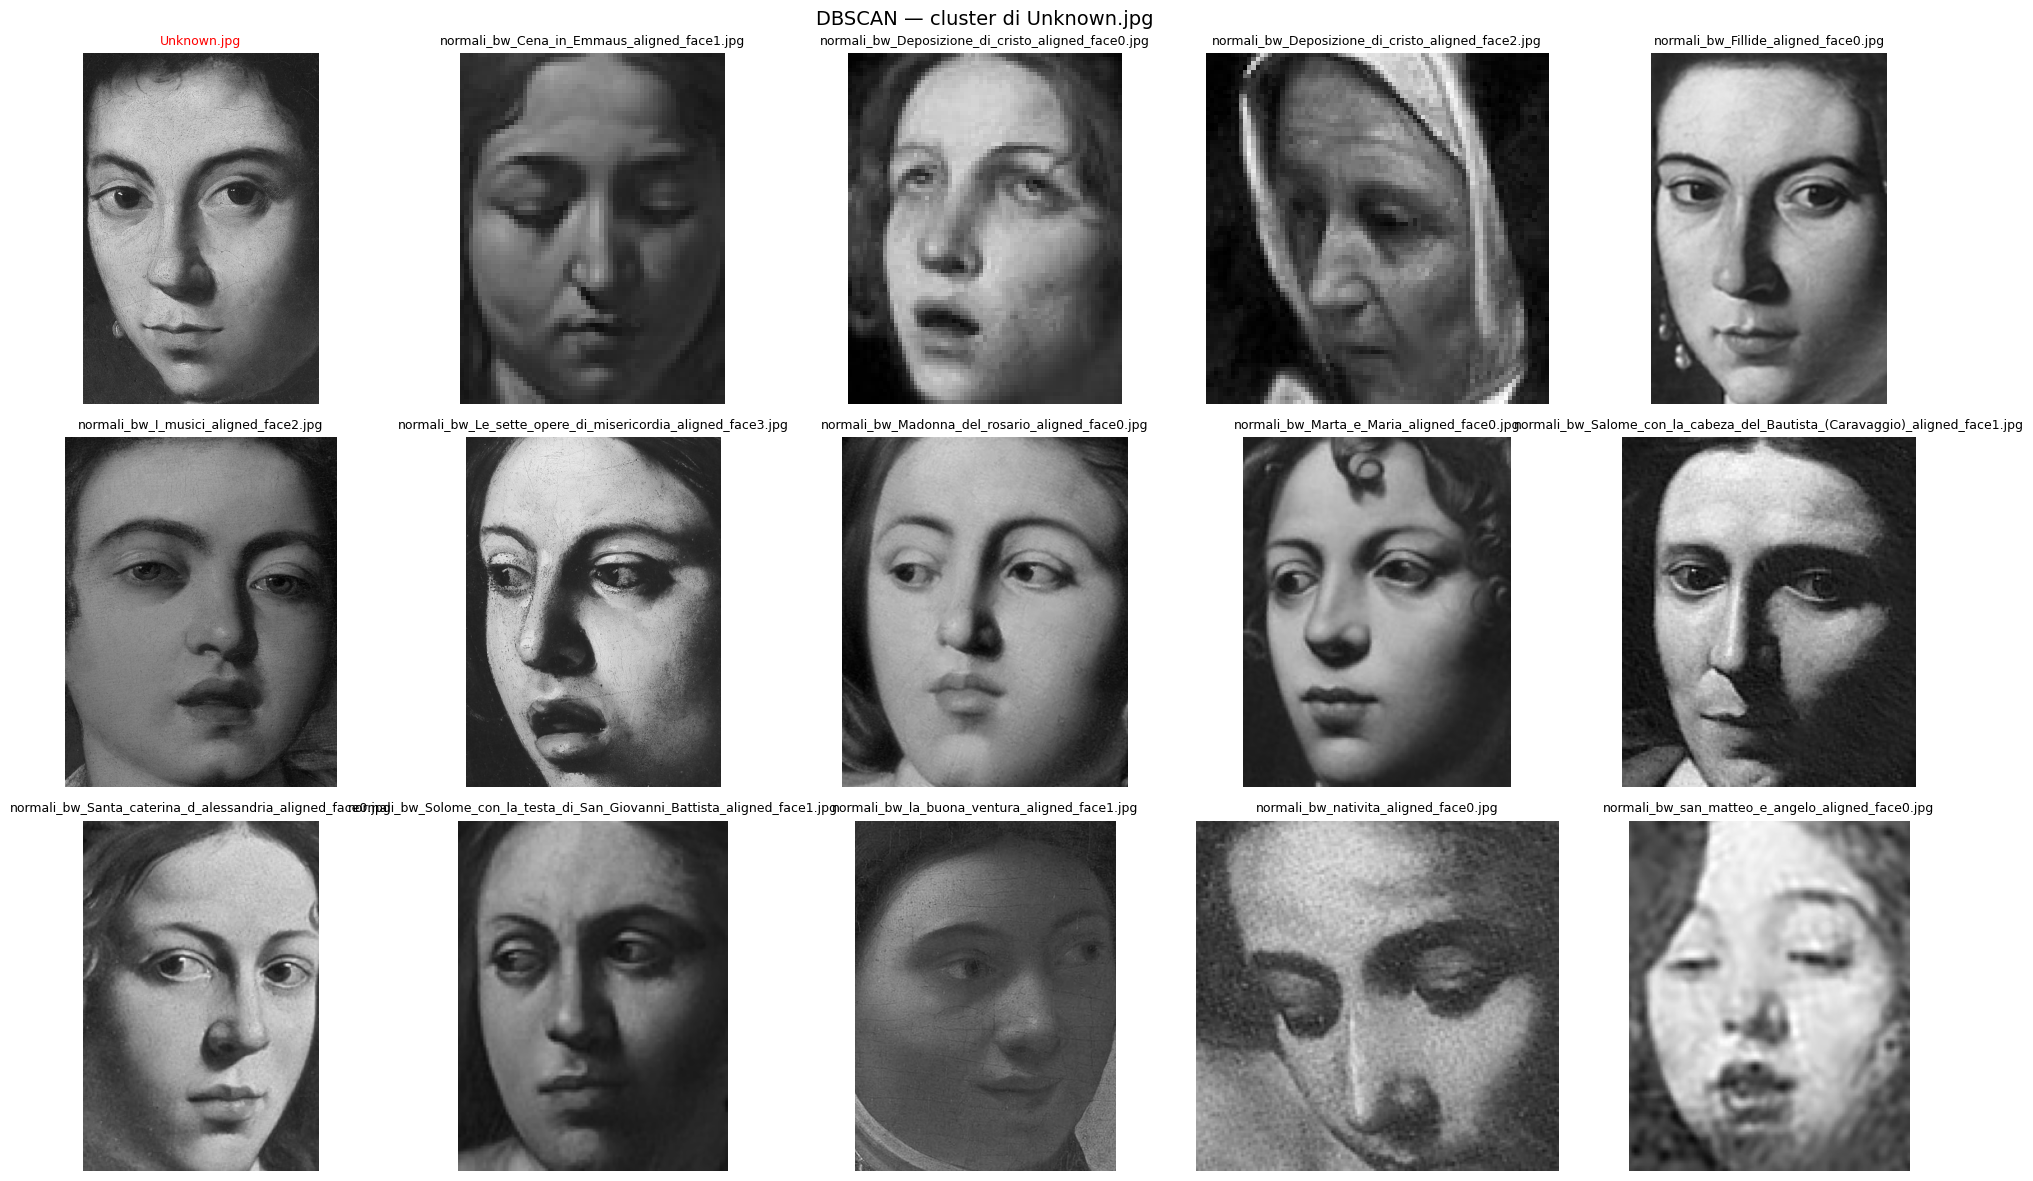


--- Similarità coseno DBSCAN (Unknown.jpg) ---
                                                                   Immagine  Similarità Coseno
                                       normali_bw_Fillide_aligned_face0.jpg             0.4744
                normali_bw_Le_sette_opere_di_misericordia_aligned_face3.jpg             0.3269
  normali_bw_Solome_con_la_testa_di_San_Giovanni_Battista_aligned_face1.jpg             0.3259
                  normali_bw_Santa_caterina_d_alessandria_aligned_face0.jpg             0.3075
                                 normali_bw_Marta_e_Maria_aligned_face0.jpg             0.2968
                              normali_bw_la_buona_ventura_aligned_face1.jpg             0.2611
normali_bw_Salome_con_la_cabeza_del_Bautista_(Caravaggio)_aligned_face1.jpg             0.2209
                           normali_bw_san_matteo_e_angelo_aligned_face0.jpg             0.2140
                           normali_bw_Madonna_del_rosario_aligned_face0.jpg             0.2131
  

In [24]:
members_db = show_cluster(results_db, 'DBSCAN — cluster di ' + nome_test)
similarity_report(members_db, 'DBSCAN')